In [1]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from scipy.optimize import brentq
from scipy.interpolate import interp1d

import seaborn as sns

In [43]:
def print_metrics(scores, labels):
    fpr, tpr, thres = roc_curve(labels, scores)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer_func = interp1d(fpr, fnr)
    eer = brentq(lambda x: eer_func(x) - x, 0., 1.)

    #print(f"AUC: {rocauc * 100:.2f}%, EER: {eer * 100:.2f}%")
    return eer, rocauc

def plot_distributions(scores, labels, ax=None, attack='Pseudo-Fakes', metrics=True):
    real_scores = scores[labels == 0]
    fake_scores = scores[labels == 1]
        
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    sns.kdeplot(real_scores, fill=True, alpha=0.5, label="Real (0)", ax=ax)
    sns.kdeplot(fake_scores, fill=True, alpha=0.5, label="Fake (1)", ax=ax)
    ax.axvline(0, linestyle="--", linewidth=2, color="red")

    ax.set_xlabel("Score")
    ax.set_ylabel("Density")
    ax.legend()
    ax.set_title(f"Target: {attack}")

    if metrics:
        eer, auc = print_metrics(scores, labels)  # <-- usa la tua funzione
        text = (
            f"N={len(scores)}\n"
            f"Real μ={real_scores.mean():.3f}\n"
            f"Fake μ={fake_scores.mean():.3f}\n"
            f"EER={eer:.3f}\n"
            f"AUC={auc:.3f}")
        ax.text(
            0.98, 0.98, text,
            transform=ax.transAxes,
            fontsize=9,
            verticalalignment='top',
            horizontalalignment='right',
            bbox=dict(boxstyle="round", alpha=0.3))

def plot_raw_scatter(scores, labels, ax=None, metrics=True):
    real_scores = scores[labels == 0]
    fake_scores = scores[labels == 1]

    if metrics:
        print_metrics(scores, labels)

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    real_y = np.zeros_like(real_scores)
    fake_y = np.ones_like(fake_scores)

    ax.scatter(real_scores, real_y, alpha=0.5, label="Real (0)")
    ax.scatter(fake_scores, fake_y, alpha=0.5, label="Fake (1)")
    ax.set_xlabel("Score")
    ax.set_ylabel("Label")
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Real", "Fake"])
    ax.legend()

def show_results(mod):
    rootpath = f'/home/smg/v-viola/moe_antideepfake/results/experts/asv19/{mod}'
    res_sanity_check = np.load(os.path.join(rootpath, 'SanityCheck', 'scores.npy'))
    lab_sanity_check = np.load(os.path.join(rootpath, 'SanityCheck', 'labels.npy'))
    
    plot_distributions(res_sanity_check, lab_sanity_check, metrics=True)
    
    fig, axes = plt.subplots(1, n_attacks, figsize=(5*n_attacks, 4))
    for i, a in enumerate(attack_list):
        res_target_check = np.load(os.path.join(rootpath, 'TargetCheck', a, 'scores.npy'))
        lab_target_check = np.load(os.path.join(rootpath, 'TargetCheck', a, 'labels.npy'))
        
        ax = axes[i] if n_attacks > 1 else axes
        plot_distributions(res_target_check, lab_target_check, ax=ax, attack=a, metrics=True)
    

# Test set - ASVspoof 2019

In [3]:
attack_list = ['A01', 'A02', 'A03', 'A04', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']
n_attacks = len(attack_list)

## Flat pitch Expert

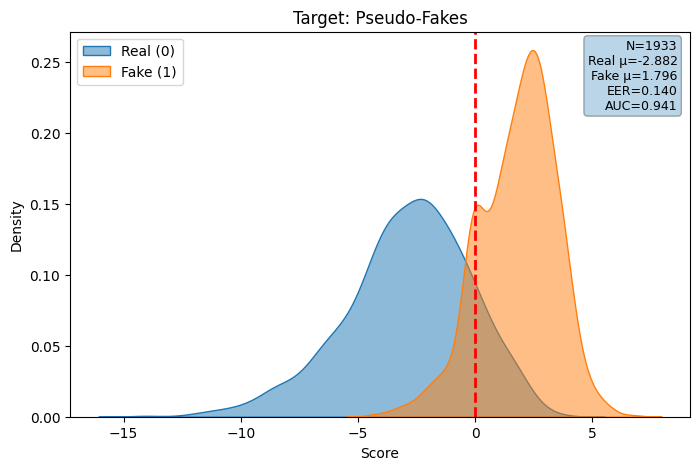

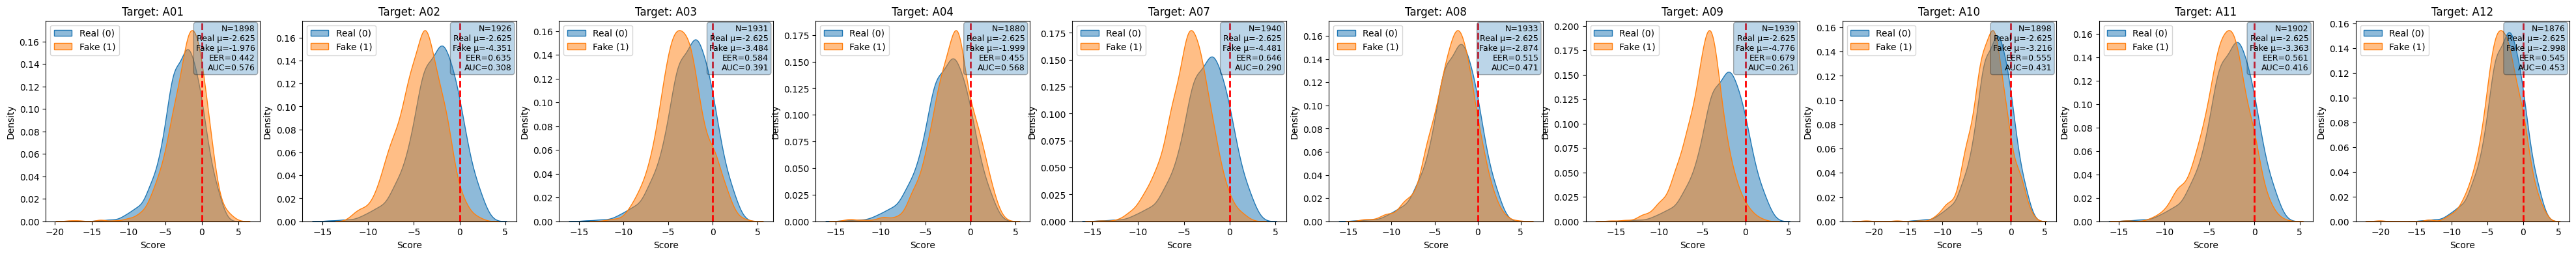

In [44]:
mod = 'flat_pitch'
show_results(mod)

## F0 inconsistency Expert

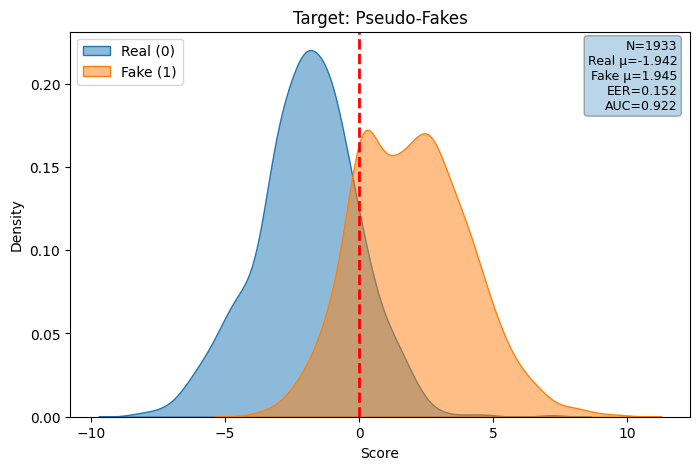

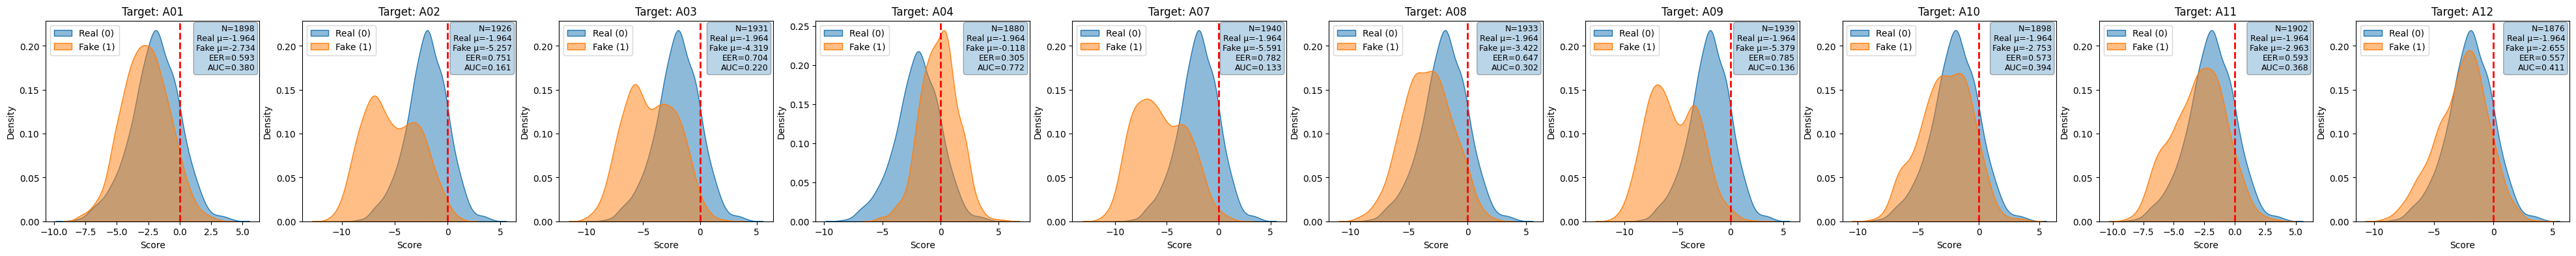

In [45]:
mod = 'f0_incons'
show_results(mod)

## Oversmoothing Expert

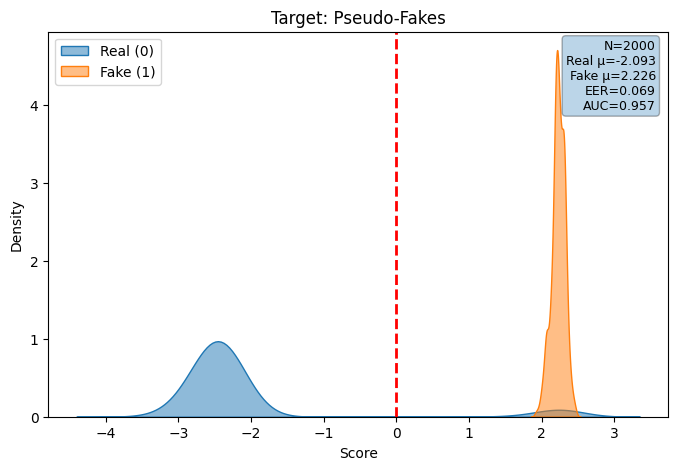

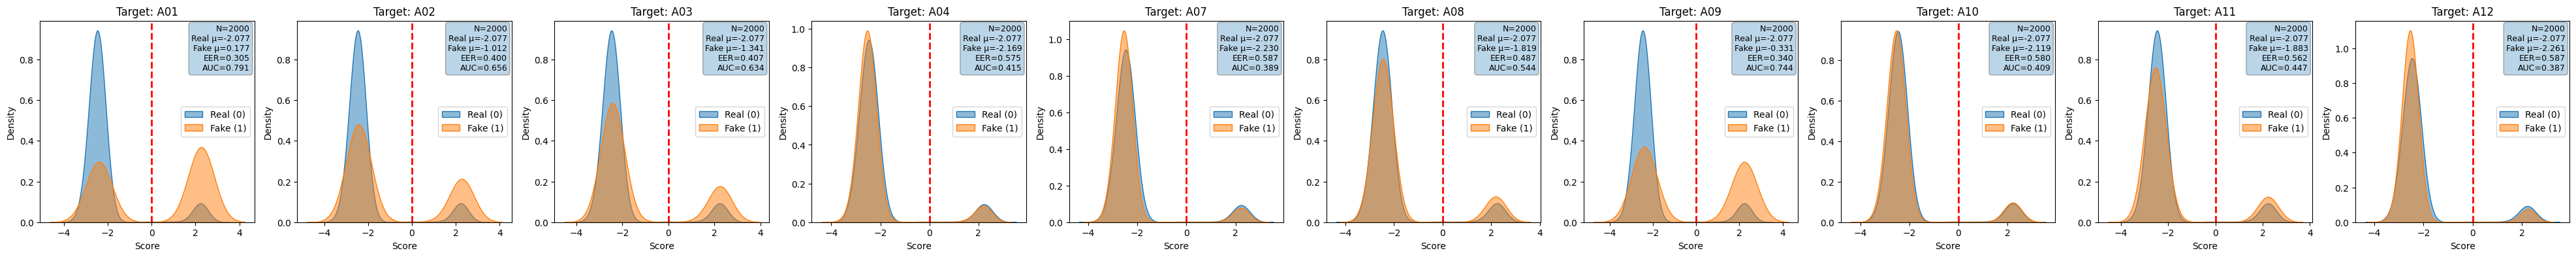

In [46]:
mod = 'oversmooth'
show_results(mod)

## Phase Expert

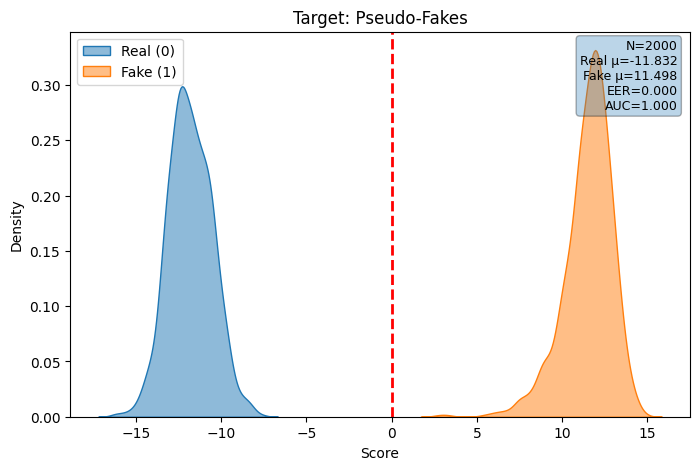

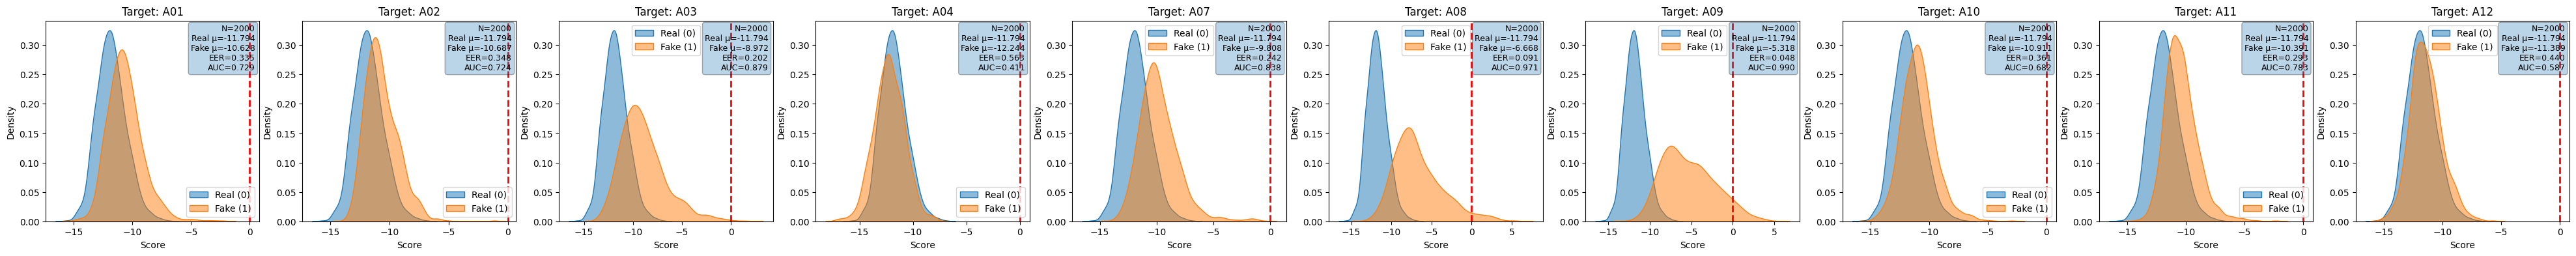

In [47]:
mod = 'min_phase'
show_results(mod)

# Energy Expert

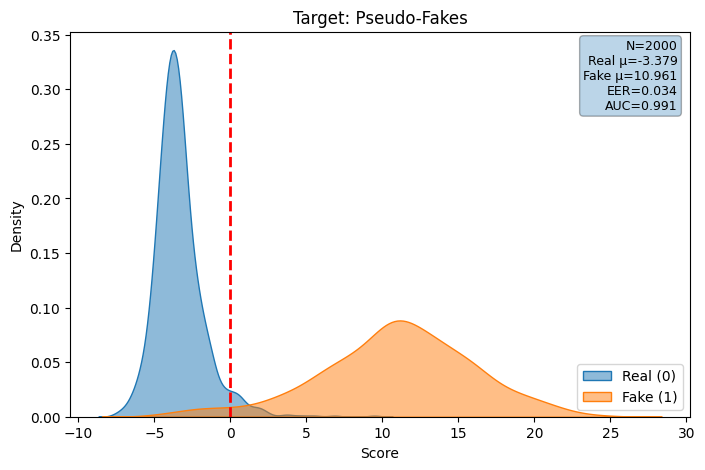

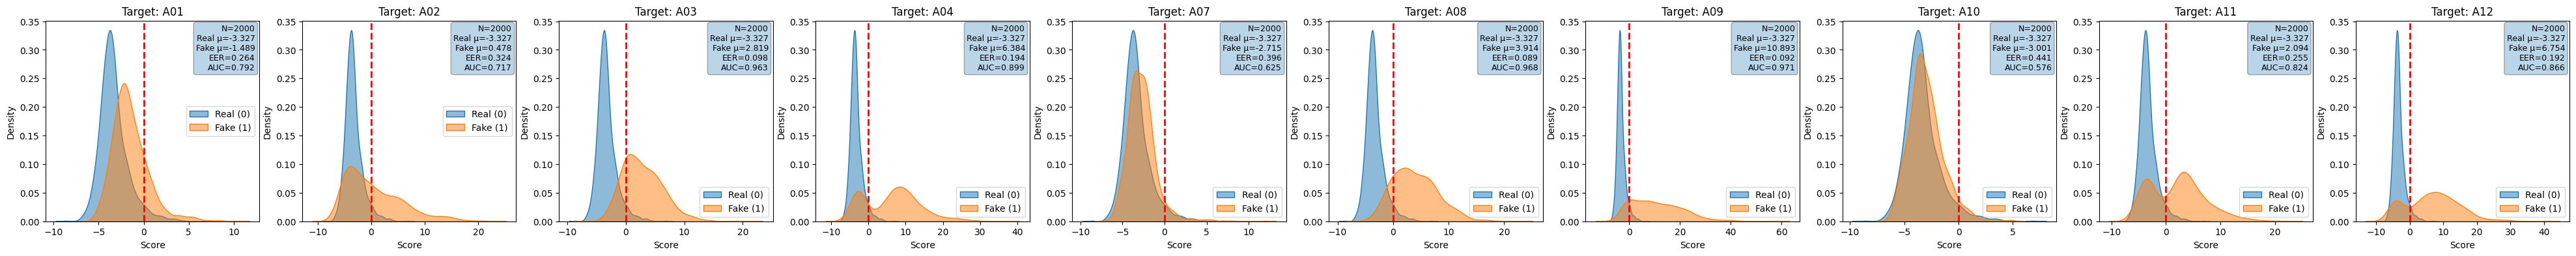

In [48]:
mod = 'energy'
show_results(mod)